# Chapter 5: Model Evaluation and Improvement

## Chapter Summary
Reliable evaluation separates model development from final assessment. This chapter covers cross-validation, stratification, grid search, nested validation logic, and metrics for imbalanced binary, multiclass, and regression tasks.

## Theoretical Deep-Dive

k-fold cross-validation rotates the validation fold and summarizes variability across splits. Stratification preserves class proportions. Hyperparameters must be chosen inside cross-validation; reporting the best validation result as a final test estimate is optimistically biased.

For binary classification, precision is $TP/(TP+FP)$ and recall is $TP/(TP+FN)$. F1 is their harmonic mean. ROC-AUC ranks positives above negatives across thresholds; average precision is often more informative when positives are rare. The correct metric follows the real cost of mistakes.

**Book coverage:** cross-validation, grid search, binary/multiclass metrics, regression metrics, and metric-aware selection (Chapter 5, printed pp. 251-302).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split, cross_validate, StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression

data = load_breast_cancer()
X_train, X_test, y_train, y_test = train_test_split(data.data, data.target, stratify=data.target, random_state=42)
pipe = make_pipeline(StandardScaler(), LogisticRegression(max_iter=3000))
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
scores = cross_validate(pipe, X_train, y_train, cv=cv, scoring=["accuracy", "f1", "roc_auc"])
display(pd.DataFrame(scores)[["test_accuracy", "test_f1", "test_roc_auc"]].round(3))
print("Mean accuracy +/- SD:", f"{scores['test_accuracy'].mean():.3f} +/- {scores['test_accuracy'].std():.3f}")

,test_accuracy,test_f1,test_roc_auc
0,0.977,0.982,0.988
1,0.965,0.972,0.996
2,0.976,0.981,0.998
3,0.988,0.991,0.999
4,0.988,0.991,0.999


Mean accuracy +/- SD: 0.979 +/- 0.009


In [2]:
from sklearn.model_selection import GridSearchCV

param_grid = {
    "logisticregression__C": np.logspace(-3, 2, 6),
    "logisticregression__class_weight": [None, "balanced"],
}
search = GridSearchCV(pipe, param_grid, cv=cv, scoring="roc_auc", n_jobs=1, return_train_score=True)
search.fit(X_train, y_train)
print("Best parameters:", search.best_params_)
print(f"Best cross-validation ROC-AUC: {search.best_score_:.3f}")
print(f"Held-out test ROC-AUC: {search.score(X_test, y_test):.3f}")
results = pd.DataFrame(search.cv_results_).sort_values("rank_test_score")
display(results[["params", "mean_train_score", "mean_test_score", "std_test_score"]].head().round(3))

Best parameters: {'logisticregression__C': np.float64(1.0), 'logisticregression__class_weight': None}
Best cross-validation ROC-AUC: 0.996
Held-out test ROC-AUC: 0.998


,params,mean_train_score,mean_test_score,std_test_score
6,"{'logisticregression__C': 1.0, 'logisticregres...",0.997,0.996,0.004
7,"{'logisticregression__C': 1.0, 'logisticregres...",0.998,0.996,0.004
5,"{'logisticregression__C': 0.1, 'logisticregres...",0.996,0.996,0.003
4,"{'logisticregression__C': 0.1, 'logisticregres...",0.996,0.995,0.003
3,"{'logisticregression__C': 0.01, 'logisticregre...",0.993,0.993,0.005


              precision    recall  f1-score   support

   malignant       0.98      0.98      0.98        53
      benign       0.99      0.99      0.99        90

    accuracy                           0.99       143
   macro avg       0.99      0.99      0.99       143
weighted avg       0.99      0.99      0.99       143

ROC-AUC=0.998 | Average precision=0.999


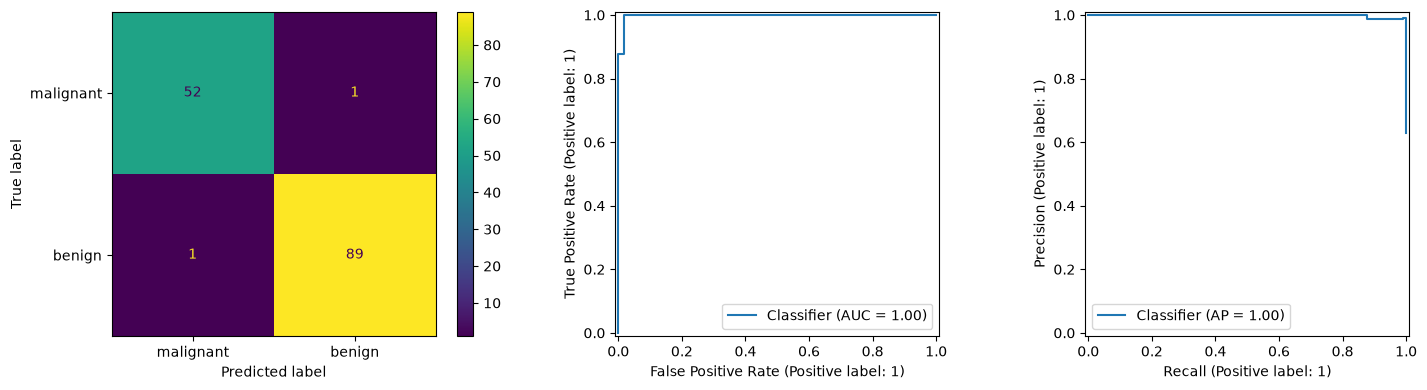

In [3]:
from sklearn.metrics import (
    ConfusionMatrixDisplay, classification_report, RocCurveDisplay,
    PrecisionRecallDisplay, roc_auc_score, average_precision_score
)

y_pred = search.predict(X_test)
y_score = search.predict_proba(X_test)[:, 1]
print(classification_report(y_test, y_pred, target_names=data.target_names))
print(f"ROC-AUC={roc_auc_score(y_test, y_score):.3f} | Average precision={average_precision_score(y_test, y_score):.3f}")
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
ConfusionMatrixDisplay.from_predictions(y_test, y_pred, display_labels=data.target_names, ax=axes[0])
RocCurveDisplay.from_predictions(y_test, y_score, ax=axes[1])
PrecisionRecallDisplay.from_predictions(y_test, y_score, ax=axes[2])
plt.tight_layout(); plt.show()

In [4]:
from sklearn.datasets import load_digits, make_regression
from sklearn.metrics import f1_score, mean_absolute_error, mean_squared_error, r2_score
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor

digits = load_digits()
Xd_train, Xd_test, yd_train, yd_test = train_test_split(digits.data, digits.target, stratify=digits.target, random_state=42)
multi = RandomForestClassifier(n_estimators=120, random_state=42).fit(Xd_train, yd_train)
multi_pred = multi.predict(Xd_test)
print("Multiclass macro-F1:", round(f1_score(yd_test, multi_pred, average="macro"), 3))

Xr, yr = make_regression(n_samples=400, n_features=12, noise=20, random_state=42)
Xr_train, Xr_test, yr_train, yr_test = train_test_split(Xr, yr, random_state=42)
reg = RandomForestRegressor(n_estimators=120, random_state=42).fit(Xr_train, yr_train)
rp = reg.predict(Xr_test)
print(f"Regression MAE={mean_absolute_error(yr_test, rp):.2f}, RMSE={mean_squared_error(yr_test, rp) ** 0.5:.2f}, R2={r2_score(yr_test, rp):.3f}")

Multiclass macro-F1: 0.964


Regression MAE=72.62, RMSE=91.16, R2=0.707


## Key Takeaways
- Cross-validation estimates variability; a single split can be misleading.
- Tune hyperparameters with training folds and reserve a final test set.
- Stratify classification splits, especially with imbalance.
- Accuracy hides error types; inspect confusion matrices, precision, recall, F1, and threshold curves.
- Select metrics from operational goals, not convenience.